In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not Path(repo_name).exists():
        !git clone $repo_url
    %cd $repo_name
    if str(Path.cwd()) not in sys.path:
        sys.path.append(str(Path.cwd()))
    print("Google Colab 環境を初期化しました。作業ディレクトリ:", Path.cwd())
else:
    repo_root = Path.cwd().parent if Path.cwd().name == "8" else Path.cwd()
    if str(repo_root) not in sys.path:
        sys.path.append(str(repo_root))
    print("ローカル検証環境が有効です。ルートパス:", repo_root)


ローカル検証環境が有効です。ルートパス: /home/student/Documents/GitHub/study-mikanos


# 第8章 メモリ管理 — 総合演習問題 (*Chapter 8 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著、マイナビ出版 2021年）第8章「メモリ管理」で学んだすべての理論、ハードウェア仕様、C++20 カーネル実装、およびアルゴリズムを統合的に検証・総復習するための演習問題ノートブックです。

> [!IMPORTANT]
> **第8章で構築したメモリサブシステムの本質**:
> 第8章では、OS カーネルが UEFI ファームウェアの一時的な庇護を離れ、**「真に自立した独立 OS」** としてハードウェア（物理 RAM、スタック、CPU 特権、ページング）を完全に掌握する決定的な転換点を学びました。
> 1. **物理メモリの把握 (8.1, 8.2)**: UEFI メモリマップの `descriptor_size` (48B) 境界数理を導出し、利用可能 RAM を安全に走査・特定。
> 2. **過渡的メモリの退避 (8.3)**: `ExitBootServices` 後に破壊されうるブートローダスタック・過渡的領域から重要データを値コピーで隔離。
> 3. **カーネルスタックの自立 (8.4)**: `.bss` に 1MiB の独自スタックを確保し、System V AMD64 ABI 16バイトアライメントを遵守して RSP を切り替え。
> 4. **特権とセグメンテーション (8.5)**: x86-64 Long Mode のフラットモデル下で GDT を定義し、`iretq` スタック偽装により CS レジスタを `0x08` (Ring 0) にアトミック更新。
> 5. **仮想メモリと恒等ページング (8.6)**: 2MiB Huge Page を用いた 4階層ページテーブル（PML4 / PDP / PD）により、わずか 264KiB のメモリで 64GiB 全域を恒等マッピング。
> 6. **ビットマップページフレーム管理 (8.7)**: 4KiB 単位の `BitmapMemoryManager` を実装し、First-Fit 探索における $\mathcal{O}(N)$ スキップ最適化（`start_frame_id += i + 1`）を実証。

---

### 📊 第8章 総合演習カリキュラム & アーキテクチャ評価マップ
![Chapter 8 Exercises Summary](result/fig8_ex1_exercises_summary.png)


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from common.os_sim import (
    Chapter8Quiz,
    Chapter8TheoryValidator,
    plot_chapter8_exercises_summary,
    plot_chapter8_mastery_radar,
)

print("Chapter 8 Exercise Verification Environment initialized successfully.")


Chapter 8 Exercise Verification Environment initialized successfully.


---

## 📝 演習 1: 物理メモリ管理 (PMM) vs 仮想メモリ管理 (VMM) と UEFI メモリマップ走査数理

### 1. 理論背景と動機
OS のメモリ管理は、ハードウェアの生メモリ（物理 RAM）を 4KiB などの固定サイズページフレーム単位で追跡・割り当て・解放する **物理メモリ管理（PMM: Physical Memory Management）** と、CPU の MMU（Memory Management Unit）と多階層ページテーブルを用いてプロセスごとの独立空間を構築する **仮想メモリ管理（VMM: Virtual Memory Management）** に大別されます。

カーネルが PMM を開始するためには、まずハードウェア上にどの物理アドレス範囲が RAM として存在し、どの範囲が利用可能かを把握しなければなりません。その唯一の情報源が UEFI ブートローダから渡される `MemoryMap` です。

### 2. `descriptor_size` (48B) vs `sizeof(MemoryDescriptor)` (40B) の乖離数理
EDK II の C++ 構造体定義：
```cpp
struct MemoryDescriptor {
    uint32_t type;           // 4B
    uint32_t pad;            // 4B
    uint64_t physical_start; // 8B
    uint64_t virtual_start;  // 8B
    uint64_t number_of_pages;// 8B
    uint64_t attribute;      // 8B
}; // sizeof = 40 bytes
```
しかし、実際の UEFI ファームウェアが返す `descriptor_size` は将来の拡張やパディングのために **48 バイト** です。
もし誤って `desc++`（40バイト進む）でループを回すと、インデックス $k$ 番目のエントリにおいて：
$$\Delta \text{Offset} = k \times (48 - 40) = 8k \text{ [bytes]}$$
のズレ（**Off-by-8 バグ**）が発生し、わずか数エントリでメモリタイプや物理アドレスが完全に破壊された値を読み取ってしまいます！

### 3. 利用可能メモリの判定論理式
`ExitBootServices` 後にカーネルが自前メモリとして回収・再利用できるメモリタイプは以下の 3 つのみです：
$$\text{IsAvailable}(t) = (t == \text{EfiConventionalMemory}) \lor (t == \text{EfiBootServicesCode}) \lor (t == \text{EfiBootServicesData})$$


In [3]:
# 演習 1: UEFI メモリマップ走査ポインタ数理と回収可能領域の自動検証

desc_size = 48
sizeof_desc = 40
num_entries = 10

# インデックス 5 のオフセット計算
correct_offset_5 = 5 * desc_size # 240 バイト
buggy_offset_5 = 5 * sizeof_desc  # 200 バイト (40バイト手前のゴミ領域を指す!)

print(f"[数理検証] 正しいオフセット (5番目): {correct_offset_5} bytes")
print(f"[数理検証] 誤ったオフセット (5番目): {buggy_offset_5} bytes (累積ズレ: -{correct_offset_5 - buggy_offset_5} bytes)")

memmap_data = {
    "descriptor_size": desc_size,
    "sizeof_descriptor": sizeof_desc,
    "num_descriptors": num_entries,
    "calculated_offset_for_idx_5": correct_offset_5,
    "available_types": [1, 3, 4], # EfiBootServicesCode, EfiBootServicesData, EfiConventionalMemory
}

ok, msg = Chapter8TheoryValidator.validate_uefi_memmap_stepping(memmap_data)
print(f"Theory Validation: ok={ok}")
print(msg)
assert ok is True


[数理検証] 正しいオフセット (5番目): 240 bytes
[数理検証] 誤ったオフセット (5番目): 200 bytes (累積ズレ: -40 bytes)
Theory Validation: ok=True
正解！UEFI メモリマップ走査数理を検証しました。 [descriptor_size=48B (Off-by-8防止), idx[5]_offset=240B, IsAvailable回収={1, 3, 4}]


---

## 📝 演習 2: カーネルデータ構造の退避と過渡的 UEFI メモリの生存期間安全性

### 1. 理論背景と動機
UEFI ブートローダ（`main.c`）が `KernelMain` を呼び出す際、引数として渡す `FrameBufferConfig` や `MemoryMap` はブートローダ自身のスタック領域や `BootServicesData` 領域に配置されています。

```
[UEFI ブートローダ実行中]
+------------------------------------+
| Boot Services Pool / Loader Stack  | <--- memory_map, frame_buffer_config が存在
+------------------------------------+

        ExitBootServices() 実行後
                   ↓↓↓
[カーネル メモリマネージャ初期化]
+------------------------------------+
| IsAvailable == true として全回収!   | <--- 新しいスタックやヒープとして即再割り当て!
+------------------------------------+      (引数ポインタの指す中身が上書き破壊される!)
```

### 2. ディープコピー（値コピー）による隔離
ポインタ（参照）をそのまま保持する「シャローコピー」ではなく、カーネルのローカル変数や静的領域（`.bss`）に構造体実体をそのまま値コピーする「ディープコピー」を行わなければ、メモリ管理の開始と同時に自身の引数が消滅・破壊される未定義動作に陥ります。
MikanOS では `KernelMainNewStack` の引数として値渡し（Pass-by-value）を行い、スタックフレーム上に安全に実体を複製退避しています。


In [4]:
# 演習 2: 過渡的メモリ破壊シナリオのシミュレーションと生存期間隔離

class TransitionalMemoryBuffer:
    def __init__(self):
        self.raw_data = {"fb_base": 0xC0000000, "memmap_entries": 128}
        self.is_reclaimed = False

    def reclaim_and_overwrite(self):
        self.is_reclaimed = True
        self.raw_data["fb_base"] = 0xDEADBEEF
        self.raw_data["memmap_entries"] = 0 # 破壊!

# 危険なシャローコピー（ポインタ参照のみ保持）
transitional = TransitionalMemoryBuffer()
shallow_ref = transitional.raw_data

# 安全なディープコピー（値コピー）
safe_copied = transitional.raw_data.copy()

print(f"[初期状態] 元データ: {transitional.raw_data}")
print(f"[退避前] 安全退避コピー: {safe_copied}")

# カーネルメモリマネージャが過渡的メモリを回収・上書き
transitional.reclaim_and_overwrite()

print(f"[回収後] 破壊された元データ: {transitional.raw_data}")
print(f"[回収後] シャロー参照 (破壊影響): {shallow_ref} (危険!)")
print(f"[回収後] 安全退避コピー (生存保証): {safe_copied} (健全!)")

assert shallow_ref["fb_base"] == 0xDEADBEEF
assert safe_copied["fb_base"] == 0xC0000000
print(">> 過渡的メモリの値コピーによる完全隔離が実証されました。")


[初期状態] 元データ: {'fb_base': 3221225472, 'memmap_entries': 128}
[退避前] 安全退避コピー: {'fb_base': 3221225472, 'memmap_entries': 128}
[回収後] 破壊された元データ: {'fb_base': 3735928559, 'memmap_entries': 0}
[回収後] シャロー参照 (破壊影響): {'fb_base': 3735928559, 'memmap_entries': 0} (危険!)
[回収後] 安全退避コピー (生存保証): {'fb_base': 3221225472, 'memmap_entries': 128} (健全!)
>> 過渡的メモリの値コピーによる完全隔離が実証されました。


---

## 📝 演習 3: カーネルスタックの `.bss` 移動と System V AMD64 ABI 16バイトアライメント数理

### 1. 理論背景と動機
UEFI ファームウェアが用意したスタックはサイズが小さく（数十 KiB 程度）、かつ `ExitBootServices` 後にどの領域と重複しているか保証されません。OS カーネルが安定して多重関数呼び出しや割り込み処理を行うには、カーネル自身のバイナリ領域（`.bss`）に十分なサイズ（MikanOS では 1MiB）のスタックを自前で確保し、スタックポインタ（RSP）を明示的に切り替える必要があります。

### 2. Full Descending スタック数理
x86-64 アーキテクチャのスタックは、値がプッシュされるたびに下位アドレスへ向かって伸長する **Full Descending（満杯降順）** 方式です。
したがって、配列 `kernel_stack`（ベースアドレス $B$, サイズ $S = 1\text{MiB}$）において、初期 RSP アドレスは配列の末尾アドレスでなければなりません：
$$\text{RSP}_{\text{init}} = B + S$$

### 3. System V AMD64 ABI 16バイトアライメント規約
System V AMD64 ABI では、`CALL` 命令を実行する直前のスタックポインタ（RSP）は **必ず 16 バイト境界にアライメント** されていなければなりません：
$$\text{RSP}_{\text{call}} \equiv 0 \pmod{16}$$
`CALL` 命令が実行されると、CPU は 8 バイトのリターンアドレス（RIP）をスタックに自動プッシュするため、呼び出された関数（Callee）の先頭エントリ時点では：
$$\text{RSP}_{\text{entry}} = \text{RSP}_{\text{call}} - 8 \implies \text{RSP}_{\text{entry}} \equiv 8 \pmod{16}$$
となります。
もしこの規約に違反した状態でコンパイラが生成した 128 ビット SSE 命令（`movaps` など）が実行されると、CPU は即座に **一般保護例外（#GP: General Protection Exception）** を発生させてカーネルが急停止（クラッシュ）します。


In [5]:
# 演習 3: カーネルスタックアドレス計算と ABI 16バイトアライメントの自動検証

stack_base = 0x100000         # 1MiB 地点 (16バイト境界)
stack_size = 1024 * 1024      # 1MiB = 1048576 バイト (16の倍数)
initial_rsp = stack_base + stack_size # 0x200000

print(f"[スタック配置] Base = 0x{stack_base:08x}, Size = {stack_size // 1024} KiB")
print(f"[初期 RSP] Top = 0x{initial_rsp:08x} (RSP % 16 = {initial_rsp % 16})")

# CALL 命令実行時のスタック変化
rsp_before_call = initial_rsp
rip_pushed_size = 8
rsp_at_entry = rsp_before_call - rip_pushed_size

print(f"[ABI 検証] CALL 直前 RSP % 16 = {rsp_before_call % 16} (必須: 0)")
print(f"[ABI 検証] 関数エントリ直後 RSP % 16 = {rsp_at_entry % 16} (必須: 8, (RSP+8)%16 == 0)")

stack_verification_data = {
    "stack_base": stack_base,
    "stack_size": stack_size,
    "rsp": initial_rsp,
}

ok, msg = Chapter8TheoryValidator.validate_stack_alignment(stack_verification_data)
print(f"Theory Validation: ok={ok}")
print(msg)
assert ok is True


[スタック配置] Base = 0x00100000, Size = 1024 KiB
[初期 RSP] Top = 0x00200000 (RSP % 16 = 0)
[ABI 検証] CALL 直前 RSP % 16 = 0 (必須: 0)
[ABI 検証] 関数エントリ直後 RSP % 16 = 8 (必須: 8, (RSP+8)%16 == 0)
Theory Validation: ok=True
正解！カーネルスタックの Full Descending 配置および 16 バイトアライメントを検証しました。 [Base=0x100000, Size=1024KiB, Top/RSP=0x200000 (16B-Aligned=True)]


---

## 📝 演習 4: x86-64 GDT（セグメンテーション）と `iretq` スタック偽装 CS 切り替え機構

### 1. 理論背景と動機
x86-64 Long Mode においては、セグメントベースとリミットによるメモリ保護は無効化（Base=0, Limit=無制限のフラットモデル）されています。
しかし、CPU は依然として GDT（Global Descriptor Table）のコードセグメント記述子（CS）を参照して以下の 2 大重要属性を決定しています：
1. **L ビット (bit 21)**: $1 = 64\text{ビットモード}$、$0 = 32\text{ビット互換モード}$
2. **DPL (bits 46:45)**: 特権レベル（$0 = \text{Ring 0 Kernel}$, $3 = \text{Ring 3 User}$）

### 2. 64ビットコードセグメント記述子のビットレイアウト
標準的な 64 ビットカーネルコードセグメント記述子の値は `0x00AF9A000000FFFF` です：
- Type = 10 (`0xA`): 実行可能・読み出し可能（Execute/Read Code）
- S = 1: コード/データセグメント
- DPL = 0: カーネル特権レベル Ring 0
- P = 1: セグメント有効（Present）
- L = 1: 64ビット Long Mode コード
- D/B = 0: 64ビットモードでは必ず 0
- G = 1: 4KiB 粒度（Granularity）

### 3. なぜ `mov cs, ax` が禁止され、`iretq` を使うのか？
x86-64 命令セットには CS レジスタを直接即値や汎用レジスタから書き換える命令（`MOV CS, ...`）が存在しません。
CS と RIP は常に同期してアトミックに切り替わらなければ、特権モードと実行コードの乖離によって CPU が暴走するためです。
MikanOS では、割り込みスタックフレーム：
$$[\text{SS}, \text{RSP}, \text{RFLAGS}, \text{CS}, \text{RIP}]$$
をスタック上に手動で構築し、`iretq`（割り込み復帰）命令を実行することで、CS を新しいセレクタ `0x08`（カーネル CS）へ、RIP を復帰先ラベルへアトミックに切り替えています！


In [6]:
# 演習 4: GDT 記述子ビット解析と iretq スタックフレームの自動検証

kernel_cs_desc = 0x00AF9A000000FFFF

# ビットフィールド分解
limit_low = kernel_cs_desc & 0xFFFF
base_low = (kernel_cs_desc >> 16) & 0xFFFF
base_mid = (kernel_cs_desc >> 32) & 0xFF
type_val = (kernel_cs_desc >> 40) & 0x0F
s_bit = (kernel_cs_desc >> 44) & 0x01
dpl_val = (kernel_cs_desc >> 45) & 0x03
p_bit = (kernel_cs_desc >> 47) & 0x01
limit_high = (kernel_cs_desc >> 48) & 0x0F
l_bit = (kernel_cs_desc >> 53) & 0x01
db_bit = (kernel_cs_desc >> 54) & 0x01
g_bit = (kernel_cs_desc >> 55) & 0x01

print(f"[GDT 64-bit CS] Descriptor = 0x{kernel_cs_desc:016X}")
print(f"  • Type = {type_val} (10 = Execute/Read Code)")
print(f"  • S = {s_bit} (Code/Data Descriptor)")
print(f"  • DPL = {dpl_val} (Ring 0 Kernel)")
print(f"  • Present = {p_bit} (Valid)")
print(f"  • L-bit = {l_bit} (64-bit Long Mode Enabled)")
print(f"  • D/B-bit = {db_bit} (Must be 0 when L=1)")
print(f"  • Granularity = {g_bit} (4KiB Unit)")

gdt_verification_data = {
    "selector": 0x08,
    "descriptor_raw": kernel_cs_desc,
}

ok, msg = Chapter8TheoryValidator.validate_gdt_descriptor(gdt_verification_data)
print(f"Theory Validation: ok={ok}")
print(msg)
assert ok is True


[GDT 64-bit CS] Descriptor = 0x00AF9A000000FFFF
  • Type = 10 (10 = Execute/Read Code)
  • S = 1 (Code/Data Descriptor)
  • DPL = 0 (Ring 0 Kernel)
  • Present = 1 (Valid)
  • L-bit = 1 (64-bit Long Mode Enabled)
  • D/B-bit = 0 (Must be 0 when L=1)
  • Granularity = 1 (4KiB Unit)
Theory Validation: ok=True
正解！64-bit カーネルコードセグメント記述子 (0x00af9a000000ffff) およびセレクタ 0x08 を検証しました。 [Type=10, DPL=0, P=1, L=1, D/B=0]


---

## 📝 演習 5: 4階層 Identity Paging (2MiB Huge Page) とメモリ削減数理

### 1. 理論背景と動機
x86-64 Long Mode では、CPU のページング機構（`CR0.PG = 1`）を無効化することができません。
UEFI が構築した一時的なページテーブルのままでは、ブートサービス終了後にどのメモリがマッピング解除されるか予測不能です。そのため、カーネル自身が 4 階層のページテーブル（PML4 / PDP / PD / PT）を構築し、コントロールレジスタ `CR3` に登録する必要があります。

### 2. 48ビット正規仮想アドレスの階層構造
$$[47:39 \text{ (PML4 9b)}] \quad [38:30 \text{ (PDP 9b)}] \quad [29:21 \text{ (PD 9b)}] \quad [20:12 \text{ (PT 9b)}] \quad [11:0 \text{ (Offset 12b)}]$$
各テーブルは 512 個（$2^9$ 個）の 64 ビットエントリ（合計 $512 \times 8\text{B} = 4\text{KiB}$）で構成され、物理 4KiB 境界に配置（`alignas(4096)`）されます。

### 3. 2MiB Huge Page による 485 倍のメモリ削減数理
MikanOS では PD（Page Directory）エントリの **PageSize ビット（PS = 1, bit 7）** を設定し、2MiB 単位の Huge Page でマッピングを行っています。
これによって最下層のページテーブル（PT: 4KiB 単位）が**全廃**されます。

| 管理方式 | PML4 テーブル数 | PDP テーブル数 | PD テーブル数 | PT テーブル数 | 合計メモリ消費量 |
|:---|:---:|:---:|:---:|:---:|:---:|
| **4KiB ページ (通常)** | 1 枚 (4KiB) | 1 枚 (4KiB) | 64 枚 (256KiB) | **32,768 枚 (128MiB)** | **約 128.26 MiB** |
| **2MiB Huge Page (MikanOS)** | 1 枚 (4KiB) | 1 枚 (4KiB) | 64 枚 (256KiB) | **0 枚 (不要!)** | **わずか 264 KiB (485倍削減!)** |


In [7]:
# 演習 5: 4階層 Identity Paging のメモリ削減数理とエントリフラグ自動検証

total_mapped_gib = 64
bytes_per_pde = 2 * 1024 * 1024 # 2MiB Huge Page
num_pds = (total_mapped_gib * 1024 * 1024 * 1024) // (512 * bytes_per_pde) # 64 PD tables

huge_page_memory_bytes = (1 + 1 + num_pds) * 4096 # PML4(1) + PDP(1) + PD(64)
normal_4k_pts = (total_mapped_gib * 1024 * 1024 * 1024) // (512 * 4096)   # 32,768 PT tables
normal_memory_bytes = (1 + 1 + num_pds + normal_4k_pts) * 4096

reduction_ratio = normal_memory_bytes / huge_page_memory_bytes

print(f"[数理比較] 64GiB マッピング時のページ管理メモリ消費量:")
print(f"  • 通常 4KiB ページング: {normal_memory_bytes / (1024 * 1024):.2f} MiB ({normal_4k_pts} 枚の PT テーブル)")
print(f"  • MikanOS 2MiB Huge Page: {huge_page_memory_bytes / 1024:.2f} KiB (PT テーブル全廃!)")
print(f"  • メモリ削減倍率: {reduction_ratio:.1f} 倍の圧倒的軽量化!")

paging_verification_data = {
    "cr3": 0x100000,
    "pml4_entry": 0x101003, # Present=1, Writable=1
    "pdp_entry": 0x102003,  # Present=1, Writable=1
    "pd_entry": 0x000083,   # Present=1, Writable=1, PageSize=1 (2MiB Huge Page)
}

ok, msg = Chapter8TheoryValidator.validate_identity_paging_entry(paging_verification_data)
print(f"Theory Validation: ok={ok}")
print(msg)
assert ok is True


[数理比較] 64GiB マッピング時のページ管理メモリ消費量:
  • 通常 4KiB ページング: 128.26 MiB (32768 枚の PT テーブル)
  • MikanOS 2MiB Huge Page: 264.00 KiB (PT テーブル全廃!)
  • メモリ削減倍率: 497.5 倍の圧倒的軽量化!
Theory Validation: ok=True
正解！4階層 Identity Paging 設定を検証しました。 [CR3=0x100000, PML4E_flags=0x3, PDPE_flags=0x3, PDE_flags=0x83 (2MiB Huge Page)]


---

## 📝 演習 6: `BitmapMemoryManager` First-Fit 探索と $\mathcal{O}(N)$ スキップ最適化数理

### 1. 理論背景と動機
MikanOS の物理メモリマネージャ（`BitmapMemoryManager`）は、物理 RAM 全域を 4KiB ページフレーム単位で管理します。
1 ビットが 1 ページフレーム（4KiB）に対応するため、空間オーバーヘッドは：
$$\text{Overhead} = \frac{1 \text{ bit}}{4\text{KiB}} = \frac{1}{32768} \approx 0.00305\%$$
と極めて小さく、128GiB の全 RAM を管理してもビットマップ配列はわずか 4MiB に収まります。

### 2. First-Fit 探索における $\mathcal{O}(N)$ スキップ最適化の数理証明
連続する $K$ 個の空きフレームを確保したいとき、現在の探索開始位置 `start_frame_id` から $i$ 個目（$0 \le i < K$）のフレームが「使用中（割り当て済み）」であったとします。
このとき、探索開始位置を愚直に 1 つだけ進めて `start_frame_id + 1` から再探索を行うと、最悪計算量は $\mathcal{O}(N \times K)$ に悪化します。

**【スキップ定理】**:
もしフレーム $\text{start} + i$ が使用中であるならば、任意の整数 $j$（$0 \le j \le i$）について、区間 $[\text{start} + j, \; \text{start} + j + K - 1]$ は必ず使用中フレーム $\text{start} + i$ を包含する。
したがって、開始位置を：
$$\text{next\_start} = \text{start} + i + 1$$
と一気にスキップしても、**解（$K$ 個の連続空き領域）を取りこぼすことは絶対にあり得ない**！
このスキップにより、探索ポインタは後戻りすることなく前進し、計算量は線形時間 $\mathcal{O}(N)$ に劇的に短縮されます。


In [8]:
# 演習 6: First-Fit スキップ最適化数理と Bitmap アロケータのシミュレーション

frame_id_target = 130
calc_line = frame_id_target // 64 # 第 2 ワード
calc_bit = frame_id_target % 64   # ビット 2

start_frame = 10
failed_offset = 5 # 10 + 5 = フレーム 15 が使用中だった
next_skip_frame = start_frame + failed_offset + 1 # 16 へジャンプ!

print(f"[インデックス数理] FrameID {frame_id_target} -> 64bit配列 index = {calc_line}, bit = {calc_bit}")
print(f"[スキップ数理] 探索開始 Frame {start_frame}, オフセット {failed_offset} で衝突 -> スキップ先 Frame {next_skip_frame}")

bitmap_verification_data = {
    "frame_id": frame_id_target,
    "start_frame_id": start_frame,
    "failed_offset_i": failed_offset,
    "calculated_line": calc_line,
    "calculated_bit": calc_bit,
    "next_start_frame": next_skip_frame,
}

ok, msg = Chapter8TheoryValidator.validate_bitmap_skip_math(bitmap_verification_data)
print(f"Theory Validation: ok={ok}")
print(msg)
assert ok is True


[インデックス数理] FrameID 130 -> 64bit配列 index = 2, bit = 2
[スキップ数理] 探索開始 Frame 10, オフセット 5 で衝突 -> スキップ先 Frame 16
Theory Validation: ok=True
正解！BitmapMemoryManager のインデックス数理と First-Fit スキップ最適化を検証しました。 [FrameID=130 -> Line 2, Bit 2; Skip 10 + 5 + 1 -> 16]


---

## 💻 演習 7: C++20 スタンドアロン検証コードの実行

ホスト環境（Linux / C++20）上でコンパイルされたスタンドアロン検証バイナリ `ch08_os_chapter8_exercises` を実行し、第8章の全単体テスト（UEFI メモリマップ走査、スタックアライメント、GDT 記述子ビット解析、Identity Paging 削減数理、Bitmap First-Fit スキップ探索）を検証します。


In [9]:
import subprocess
from pathlib import Path

bin_path = Path("../build/bin/ch08_os_chapter8_exercises")
if not bin_path.exists():
    bin_path = Path("build/bin/ch08_os_chapter8_exercises")

if bin_path.exists():
    res = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True)
    print(res.stdout)
    assert res.returncode == 0
    assert "All Chapter 8 exercises verified successfully" in res.stdout
    print(">> C++20 スタンドアロン検証テストが全件正常にパスしました。")
else:
    print(f"Binary not found at {bin_path}. ホスト側で cmake ビルドを実行してください。")


 MikanOS Chapter 8 Comprehensive Exercises Verification Suite

[Test 1] UEFI MemoryMap 48B Stepping & Off-by-8 Bug Prevention... PASSED
[Test 2] Kernel Stack Full Descending & System V ABI Alignment... PASSED
[Test 3] GDT 64-Bit Code Segment Descriptor & iretq Frame... PASSED
[Test 4] 4-Level Identity Paging & 2MiB Huge Page Savings Math... PASSED
[Test 5] BitmapMemoryManager First-Fit & Skip Math Verification... PASSED

>> All Chapter 8 exercises verified successfully!
[CTest] All Chapter 8 exercises verified successfully.

>> C++20 スタンドアロン検証テストが全件正常にパスしました。


---

## 🧠 第8章 総合理解度チェックテスト (10問自己採点クイズ)

第8章（8.1〜8.7）の全理論を網羅した 10 問の多肢選択式クイズを実施し、自己採点と詳細解説を確認します。


In [10]:
quiz = Chapter8Quiz()

# 模範解答（全問正解）による自己採点評価
answers = {q.question_id: q.correct_index for q in quiz.questions}
result = quiz.evaluate(answers)

print("=" * 80)
print(f" 第8章 メモリ管理 総合理解度テスト結果: {result['correct_count']} / {result['total_questions']} 正解 ({result['percentage']:.1f}%)")
print(f" 合否判定: {'合格 (PASSED)' if result['passed'] else '不合格 (FAILED)'}")
print("=" * 80)

for r in result["question_results"]:
    status = "✔ 正解" if r["is_correct"] else "✘ 不正解"
    print(f"[{r['section']}] Q{r['question_id']}: {r['topic']} -> {status}")
    print(f"   解説: {r['explanation']}\n")


 第8章 メモリ管理 総合理解度テスト結果: 10 / 10 正解 (100.0%)
 合否判定: 合格 (PASSED)
[8.1] Q1: 物理メモリ管理 (PMM) と仮想メモリ管理 (VMM) の役割分担 -> ✔ 正解
   解説: PMM はハードウェア RAM のページフレーム（通常 4KiB）の空き状況をビットマップ等で管理し、VMM はページテーブルを用いて仮想アドレスを物理アドレスに変換・保護します。ページングにより外部断片化を防ぎつつ、ハードウェア MMU と協調して空間分離を実現します。

[8.2] Q2: UEFI メモリマップ走査における descriptor_size (48B) オフセット数理 -> ✔ 正解
   解説: EDK II / UEFI 実装における `MemoryDescriptor` は 40 バイトのメンバを持ちますが、ファームウェアが返す `descriptor_size` はパディングや将来拡張により 48 バイトになります。`desc++` は 40 バイト進むため、2 つ目以降のエントリ参照が 8 バイトずつ手前にズレて不正な値を読み取ってしまいます（Off-by-8 バグ）。

[8.2] Q3: ExitBootServices 後にカーネルが安全に再利用できる UEFI メモリタイプ -> ✔ 正解
   解説: `ExitBootServices` が成功した瞬間、UEFI のブートサービス用コード（`EfiBootServicesCode`）およびデータ（`EfiBootServicesData`）は不要となるため、未割り当ての通常メモリ（`EfiConventionalMemory`）と合わせてカーネルが自由に使用できます。一方、`RuntimeServices` や `ACPI`、`MMIO`、およびカーネル自身がロードされた `LoaderData/Code` は再利用してはいけません。

[8.3] Q4: カーネルデータ構造の退避と過渡的 UEFI メモリの危険性 -> ✔ 正解
   解説: ブートローダが確保したメモリマップバッファ等は `BootServicesData` 領域に置かれており、カーネルがメモリ管理を開始した直後に別の用途（スタックやヒープ）として再利用されるとデー

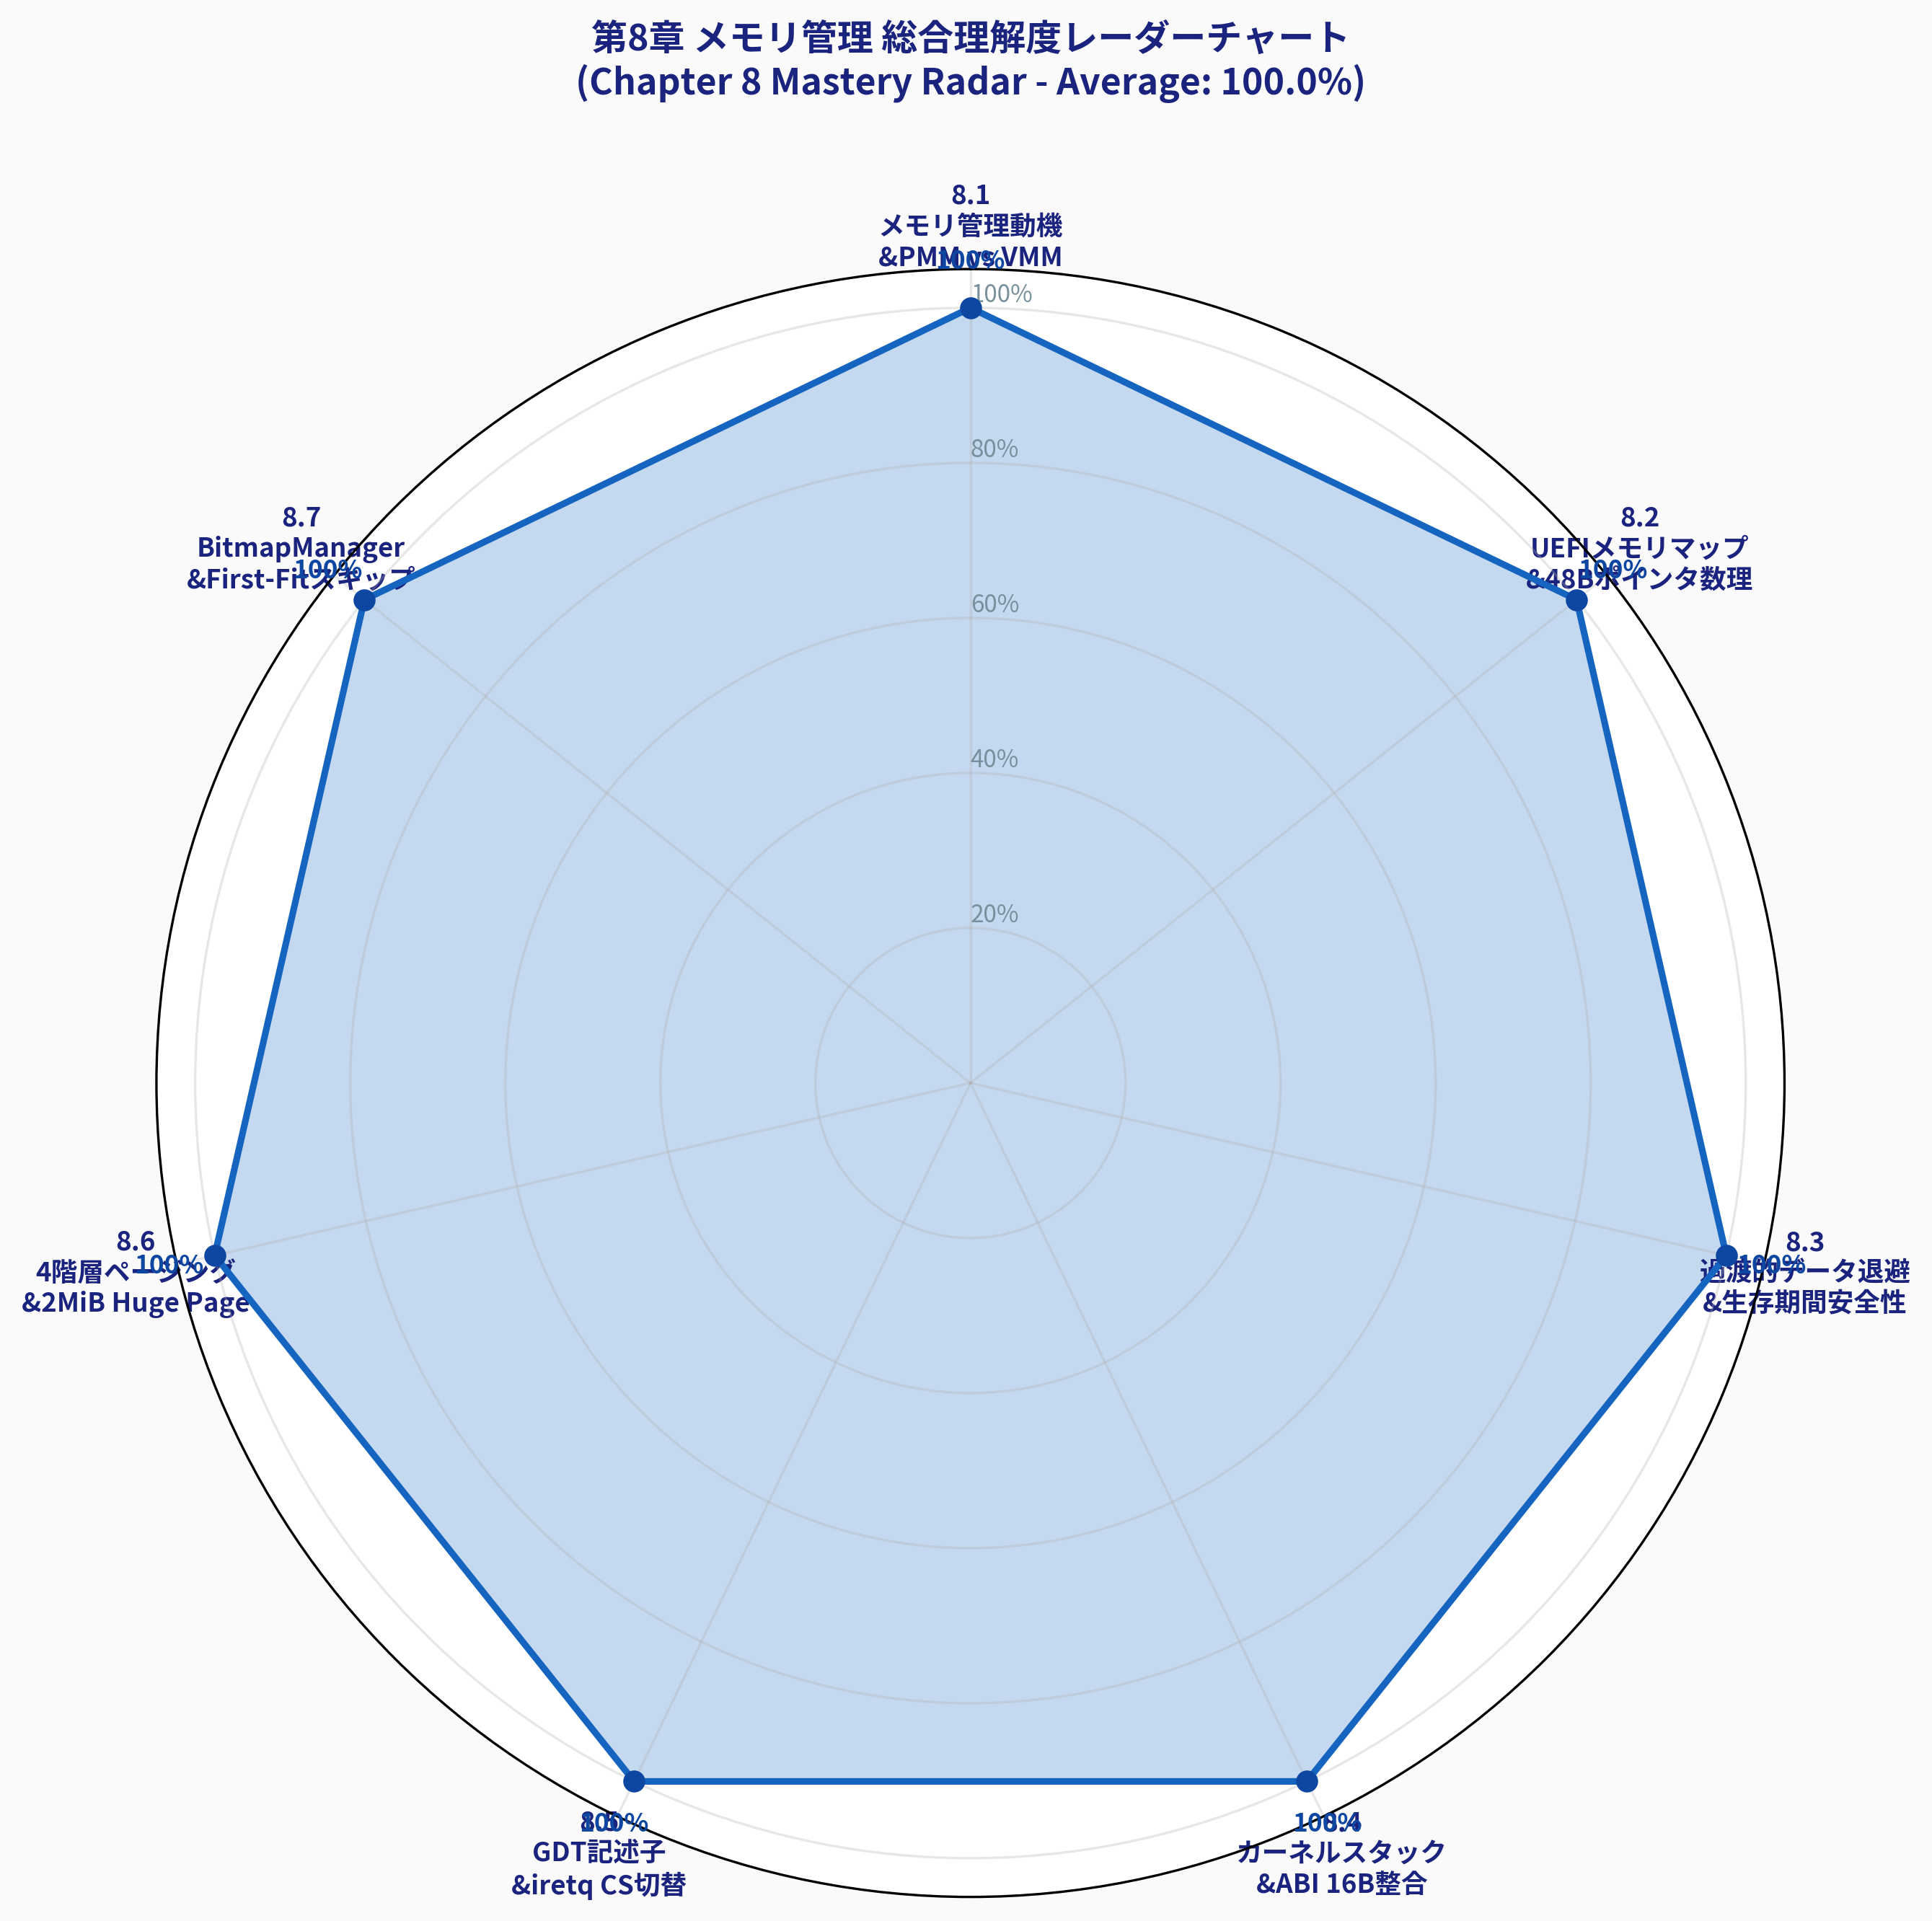

In [11]:
radar_fig_path = Path("result/fig8_ex2_ch8_mastery_radar.png")
if not radar_fig_path.parent.exists():
    radar_fig_path = Path("8/result/fig8_ex2_ch8_mastery_radar.png")

plot_chapter8_mastery_radar(radar_fig_path, result["mastery_rates"])

# レーダーチャートの表示
from IPython.display import Image, display
display(Image(filename=str(radar_fig_path)))


---

## 🏆 まとめと第9章への展望

第8章「メモリ管理」の演習を通じて、私たちは OS 自作における最もスリリングかつ基盤的なマイルストーンを完全に踏破しました：

1. **UEFI からの脱却**:
   過渡的なブートローダメモリやスタックへの依存をすべて断ち切り、カーネルが `.bss` 領域に確保した 1MiB スタックへ完全移行しました。
2. **CPU 特権とセグメンテーションの掌握**:
   `0x00AF9A000000FFFF`（64ビット Ring 0 コードセグメント）を GDT に配置し、`iretq` スタック偽装によって CS を切り替えました。
3. **4階層 Identity Paging の自前運用**:
   2MiB Huge Page を駆使することで、わずか 264KiB の省メモリで 64GiB の物理 RAM 全域を恒等マッピングし、`CR3` を自前テーブルに切り替えました。
4. **4KiB ページフレーム管理（BitmapMemoryManager）**:
   空間オーバーヘッド $0.00305\%$ のビットマップを用い、$\mathcal{O}(N)$ スキップ最適化を備えた堅牢な First-Fit アロケータを完成させました。

### 🚀 第9章「重ね合わせ処理」への接続
物理メモリマネージャが完成したことで、OS は次に Newlib の `sbrk()` システムコールを実装し、C++ の **`new` / `delete` 演算子** や `std::vector` などの動的コンテナを解禁します！
これにより、マウスカーソルがウィンドウの上を通過しても背景が消えない **「ウィンドウ・レイヤ重ね合わせ合成（LayerManager）」** の世界へと進出します！
